# Análise de dados SECOM utilizando auxílio de LLM (Gemini)


**Prompt:** A etapa inicial é baixar o dataset 'secom' do seguinte endereço: https://archive.ics.uci.edu/static/public/179/secom.zip, armazená-lo em um diretório chamado 'dataset', se necessário crie o diretório, extrair o conteúdo compactado e por fim excluir o arquivo .zip ogirinal. 

In [50]:
# SETUP
from pathlib import Path
import urllib.request
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold


RANDOM_STATE = 42


In [4]:
# Definindo o diretório do dataset e garantindo sua existência
DATA_DIR = Path("dataset")
DATA_PATH = DATA_DIR
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Caminhos para download e extração
ZIP_PATH = DATA_DIR / "secom.zip"
URL = "https://archive.ics.uci.edu/static/public/179/secom.zip"

# Baixando o arquivo zip do SECOM
print("Baixando o dataset SECOM...")
urllib.request.urlretrieve(URL, ZIP_PATH)

# Extraindo o conteúdo compactado
print("Extraindo os arquivos...")
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

# Excluindo o arquivo .zip original
ZIP_PATH.unlink()
print("Download, extração e limpeza concluídos com sucesso.")

Baixando o dataset SECOM...
Extraindo os arquivos...
Download, extração e limpeza concluídos com sucesso.


**Prompt:** Faça a carga e inspeção inicial dos dados extraídos de cada arquivo separadamente.

In [7]:
# Carregando os arquivos de dados e labels do SECOM
# O dataset secom.data contém os atributos (espaço-separados) e secom_labels.data contém a classe e o timestamp.
data_file = DATA_PATH / "secom.data"
labels_file = DATA_PATH / "secom_labels.data"

df_data = pd.read_csv(data_file, sep=" ", header=None)
df_labels = pd.read_csv(labels_file, sep=" ", header=None, names=["class", "timestamp"])

# Inspeção inicial das dimensões e primeiras linhas de cada arquivo
print("--- DF DATA ---")
print(f"Shape: {df_data.shape}")
display(df_data.head())

print("\n--- DF LABELS ---")
print(f"Shape: {df_labels.shape}")
display(df_labels.head())

--- DF DATA ---
Shape: (1567, 590)


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432



--- DF LABELS ---
Shape: (1567, 2)


,class,timestamp
0,-1,19/07/2008 11:55:00
1,-1,19/07/2008 12:32:00
2,1,19/07/2008 13:17:00
3,-1,19/07/2008 14:43:00
4,-1,19/07/2008 15:22:00


**Prompt:** Carregue e combine as colunas em um único dataframe 'df', começando com a coluna de timestamp, usando sua formatação completa para data e hora. Em seguida a coluna alvo. Por fim as colunas ordenadas com o label enumerado no formato 'Sensor_x' em que o x é o número da coluna original. 

In [8]:
# Combinando o timestamp, a classe e as features em um único DataFrame 'df'
# O timestamp está na segunda coluna de df_labels e a classe na primeira.
df = pd.DataFrame()
df['timestamp'] = pd.to_datetime(df_labels['timestamp'], format='%d/%m/%Y %H:%M:%S')
df['class'] = df_labels['class']

# Adicionando as colunas de sensores renomeadas no formato 'Sensor_x' (onde x é o índice original 0 a 589)
sensor_columns = {col: f"Sensor_{col}" for col in df_data.columns}
df_sensors = df_data.rename(columns=sensor_columns)

# Concatenando todas as partes no DataFrame final 'df'
df = pd.concat([df, df_sensors], axis=1)

# Checagem de sanidade
print(f"Shape final do DataFrame df: {df.shape}")
print(df.dtypes.head(5))
display(df.head())

Shape final do DataFrame df: (1567, 592)
timestamp    datetime64[us]
class                 int64
Sensor_0            float64
Sensor_1            float64
Sensor_2            float64
dtype: object


,timestamp,class,Sensor_0,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,Sensor_6,Sensor_7,...,Sensor_580,Sensor_581,Sensor_582,Sensor_583,Sensor_584,Sensor_585,Sensor_586,Sensor_587,Sensor_588,Sensor_589
0,2008-07-19 11:55:00,-1,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,2008-07-19 12:32:00,-1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2008-07-19 13:17:00,1,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2008-07-19 14:43:00,-1,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,2008-07-19 15:22:00,-1,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


In [51]:
# def summarize_missing(data: pd.DataFrame) -> pd.DataFrame:
#     """Retorna contagem e percentual de valores ausentes (NaN) por coluna, ordenados de forma decrescente."""
#     n_missing = data.isna().sum()
#     pct_missing = (n_missing / len(data)) * 100
    
#     summary = pd.DataFrame({
#         "n_missing": n_missing,
#         "pct_missing": pct_missing
#     }).query("n_missing > 0").sort_values("pct_missing", ascending=False)
    
#     return summary

# missing_summary = summarize_missing(df)
# print(f"Total de colunas com valores ausentes: {len(missing_summary)}")
# display(missing_summary)

In [52]:
# df.isna().mean().sort_values(ascending=False)

**Prompt:** Plote um gráfico de barras que relacione sensor x seu percentural de dados faltantes. Mantenha na horizontal a sequencia original de sensores. 

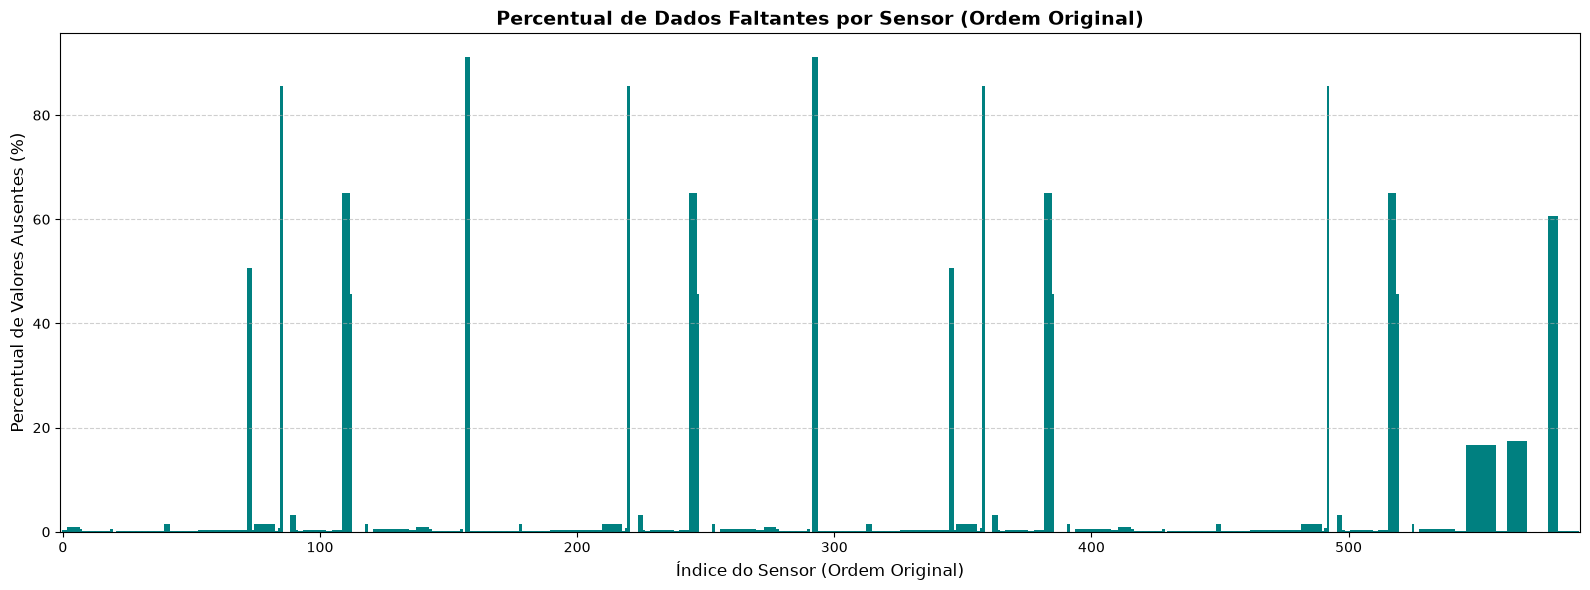

In [10]:
# Calculando o percentual de dados faltantes para cada sensor na ordem original
sensor_cols = [col for col in df.columns if col.startswith("Sensor_")]
missing_sensors_series = df[sensor_cols].isna().mean() * 100

# Plotando o gráfico de barras
plt.figure(figsize=(16, 6))
plt.bar(range(len(sensor_cols)), missing_sensors_series.values, color='teal', width=1.0)
plt.title("Percentual de Dados Faltantes por Sensor (Ordem Original)", fontsize=14, fontweight='bold')
plt.xlabel("Índice do Sensor (Ordem Original)", fontsize=12)
plt.ylabel("Percentual de Valores Ausentes (%)", fontsize=12)
plt.xlim(-1, len(sensor_cols))
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Prompt:** Plote um gráfico de barras que mostre a distribuição de valores faltantes, NaN, pelos sensores 

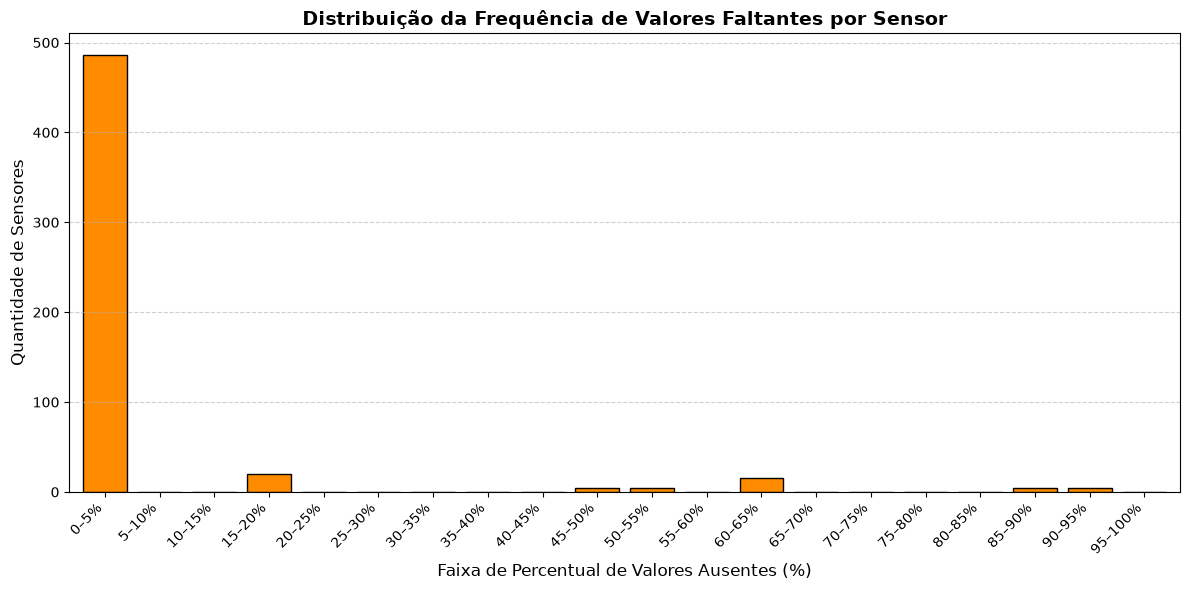

In [11]:
# Calculando o percentual de dados faltantes por sensor
sensor_cols = [col for col in df.columns if col.startswith("Sensor_")]
missing_sensors = df[sensor_cols].isna().mean() * 100

# Criando faixas (bins) para agrupar o percentual de valores faltantes
bins = range(0, int(missing_sensors.max()) + 10, 5)
binned_missing = pd.cut(missing_sensors, bins=bins).value_counts().sort_index()

# Formatando os rótulos das faixas para melhor legibilidade no gráfico de barras
binned_missing.index = [f"{int(interval.left)}–{int(interval.right)}%" for interval in binned_missing.index]

# Plotando o gráfico de barras da distribuição de frequências
plt.figure(figsize=(12, 6))
binned_missing.plot(kind='bar', color='darkorange', edgecolor='black', width=0.8)
plt.title("Distribuição da Frequência de Valores Faltantes por Sensor", fontsize=14, fontweight='bold')
plt.xlabel("Faixa de Percentual de Valores Ausentes (%)", fontsize=12)
plt.ylabel("Quantidade de Sensores", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Prompt:** Mostre os sensores com variância nula.

In [68]:
# Identificando as colunas de sensores e calculando a variância
sensor_cols = [col for col in df.columns if col.startswith("Sensor_")]
sensor_variances = df[sensor_cols].var()

# Filtrando os sensores com variância igual a zero ou NaN (nula)
zero_var_mask = (sensor_variances == 0) | (sensor_variances.isna())
zero_var_sensors = sensor_variances[zero_var_mask]

# Exibindo a lista de sensores com variância nula e a quantidade total
print(f"Total de sensores com variância nula ou NaN: {len(zero_var_sensors)}")
print("\nLista dos primeiros sensores com variância nula:")
display(zero_var_sensors.head(10))

Total de sensores com variância nula ou NaN: 116

Lista dos primeiros sensores com variância nula:


Sensor_5      0.0
Sensor_13     0.0
Sensor_42     0.0
Sensor_49     0.0
Sensor_52     0.0
Sensor_69     0.0
Sensor_97     0.0
Sensor_141    0.0
Sensor_149    0.0
Sensor_178    0.0
dtype: float64

**Prompt**: Remover os sensores com variância nula 

In [12]:
# Criando uma cópia para preservar o DataFrame original conforme as convenções
df_clean = df.copy()

# Identificando as colunas de sensores
sensor_cols = [col for col in df_clean.columns if col.startswith("Sensor_")]

# Calculando a variância dos sensores
sensor_variances = df_clean[sensor_cols].var()

# Identificando colunas com variância nula (zero ou NaN)
zero_var_cols = sensor_variances[(sensor_variances == 0) | (sensor_variances.isna())].index

# Removendo as colunas com variância nula de df_clean
df_clean = df_clean.drop(columns=zero_var_cols)

# Checagem de sanidade
print(f"Shape original do DataFrame df: {df.shape}")
print(f"Shape do DataFrame df_clean após remoção: {df_clean.shape}")
print(f"Total de colunas de sensores removidas: {len(zero_var_cols)}")

Shape original do DataFrame df: (1567, 592)
Shape do DataFrame df_clean após remoção: (1567, 476)
Total de colunas de sensores removidas: 116


In [13]:
df_clean

,timestamp,class,Sensor_0,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_6,Sensor_7,Sensor_8,...,Sensor_580,Sensor_581,Sensor_582,Sensor_583,Sensor_584,Sensor_585,Sensor_586,Sensor_587,Sensor_588,Sensor_589
0,2008-07-19 11:55:00,-1,3030.93,2564.00,2187.7333,1411.1265,1.3602,97.6133,0.1242,1.5005,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,2008-07-19 12:32:00,-1,3095.78,2465.14,2230.4222,1463.6606,0.8294,102.3433,0.1247,1.4966,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2008-07-19 13:17:00,1,2932.61,2559.94,2186.4111,1698.0172,1.5102,95.4878,0.1241,1.4436,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2008-07-19 14:43:00,-1,2988.72,2479.90,2199.0333,909.7926,1.3204,104.2367,0.1217,1.4882,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,2008-07-19 15:22:00,-1,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.3967,0.1235,1.5031,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1562,2008-10-16 15:13:00,-1,2899.41,2464.36,2179.7333,3085.3781,1.4843,82.2467,0.1248,1.3424,...,0.0047,203.1720,0.4988,0.0143,0.0039,2.8669,0.0068,0.0138,0.0047,203.1720
1563,2008-10-16 20:49:00,-1,3052.31,2522.55,2198.5667,1124.6595,0.8763,98.4689,0.1205,1.4333,...,NaN,NaN,0.4975,0.0131,0.0036,2.6238,0.0068,0.0138,0.0047,203.1720
1564,2008-10-17 05:26:00,-1,2978.81,2379.78,2206.3000,1110.4967,0.8236,99.4122,0.1208,NaN,...,0.0025,43.5231,0.4987,0.0153,0.0041,3.0590,0.0197,0.0086,0.0025,43.5231
1565,2008-10-17 06:01:00,-1,2894.92,2532.01,2177.0333,1183.7287,1.5726,98.7978,0.1213,1.4622,...,0.0075,93.4941,0.5004,0.0178,0.0038,3.5662,0.0262,0.0245,0.0075,93.4941


**Prompt:** Realize o tratamento de valores ausentes / imputação 

In [ ]:
# Separando as colunas de sensores restantes em df_clean
sensor_cols_clean = [col for col in df_clean.columns if col.startswith("Sensor_")]

# Utilizando o SimpleImputer com a estratégia de mediana para tratar os valores ausentes (NaN)
imputer = SimpleImputer(strategy='median') # 'mean', 'median', 'most_frequent', ...

# Aplicando a imputação apenas nas colunas de sensores de df_clean
df_clean[sensor_cols_clean] = imputer.fit_transform(df_clean[sensor_cols_clean])

# Checagem de sanidade: verificando se ainda restam valores nulos nas colunas de sensores
remaining_nulls = df_clean[sensor_cols_clean].isna().sum().sum()
print(f"Shape de df_clean: {df_clean.shape}")
print(f"Total de valores nulos restantes nos sensores: {remaining_nulls}")
display(df_clean.head(3))

Shape de df_clean: (1567, 476)
Total de valores nulos restantes nos sensores: 0


,timestamp,class,Sensor_0,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_6,Sensor_7,Sensor_8,...,Sensor_580,Sensor_581,Sensor_582,Sensor_583,Sensor_584,Sensor_585,Sensor_586,Sensor_587,Sensor_588,Sensor_589
0,2008-07-19 11:55:00,-1,3030.93,2564.00,2187.7333,1411.1265,1.3602,97.6133,0.1242,1.5005,...,0.0047,72.2889,0.5005,0.0118,0.0035,2.3630,0.0205,0.0148,0.0046,71.9005
1,2008-07-19 12:32:00,-1,3095.78,2465.14,2230.4222,1463.6606,0.8294,102.3433,0.1247,1.4966,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2008-07-19 13:17:00,1,2932.61,2559.94,2186.4111,1698.0172,1.5102,95.4878,0.1241,1.4436,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602


**Prompt:** Faça EDA(Análise Exploratórioa de Dados) univariada e bivariada

--- Distribuição da Variável Alvo ('class') ---


class
-1    1463
 1     104
Name: count, dtype: int64

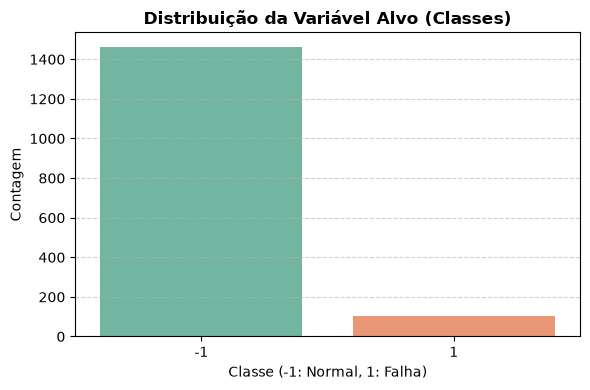

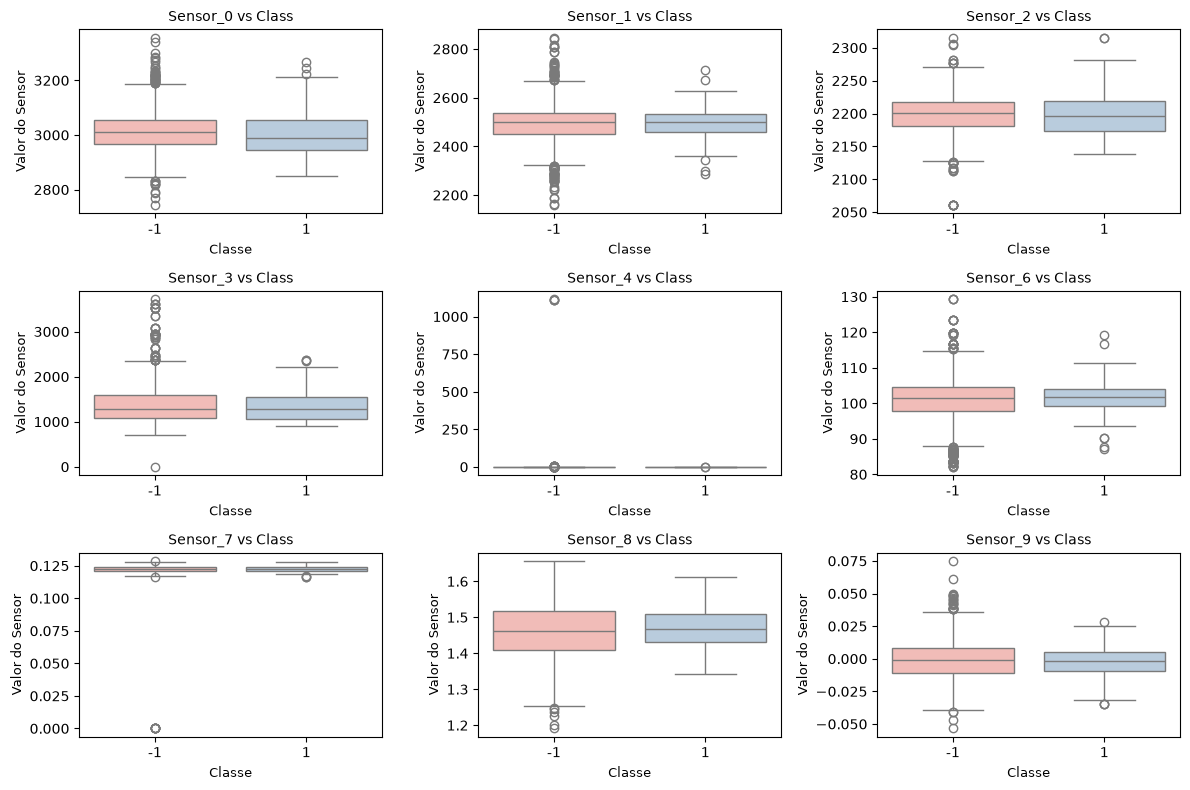

In [16]:
# 1. EDA Univariada: Distribuição da variável alvo ('class')
print("--- Distribuição da Variável Alvo ('class') ---")
class_counts = df_clean['class'].value_counts()
display(class_counts)

plt.figure(figsize=(6, 4))
sns.countplot(x='class', hue='class', data=df_clean, palette='Set2', legend=False)
plt.title("Distribuição da Variável Alvo (Classes)", fontsize=12, fontweight='bold')
plt.xlabel("Classe (-1: Normal, 1: Falha)", fontsize=10)
plt.ylabel("Contagem", fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 2. EDA Bivariada: Correlação de alguns sensores com a classe ou análise visual preliminar
# Selecionando os primeiros 9 sensores para ilustrar a relação bivariada com a classe
sample_sensors = [col for col in df_clean.columns if col.startswith("Sensor_")][:9]

plt.figure(figsize=(12, 8))
for i, col in enumerate(sample_sensors, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x='class', y=col, hue='class', data=df_clean, palette='Pastel1', legend=False)
    plt.title(f"{col} vs Class", fontsize=10)
    plt.xlabel("Classe", fontsize=9)
    plt.ylabel("Valor do Sensor", fontsize=9)

plt.tight_layout()
plt.show()

In [24]:
df_clean['Sensor_4'].loc[df_clean['Sensor_4'] > 250]
#df_clean['Sensor_4'].loc[df_clean.Sensor_4>250]

1304    1112.1600
1320    1112.0769
1446    1114.5366
1456    1112.4728
Name: Sensor_4, dtype: float64

**Prompt:** Plotar o valor do sensor_4 ao longo do tempo

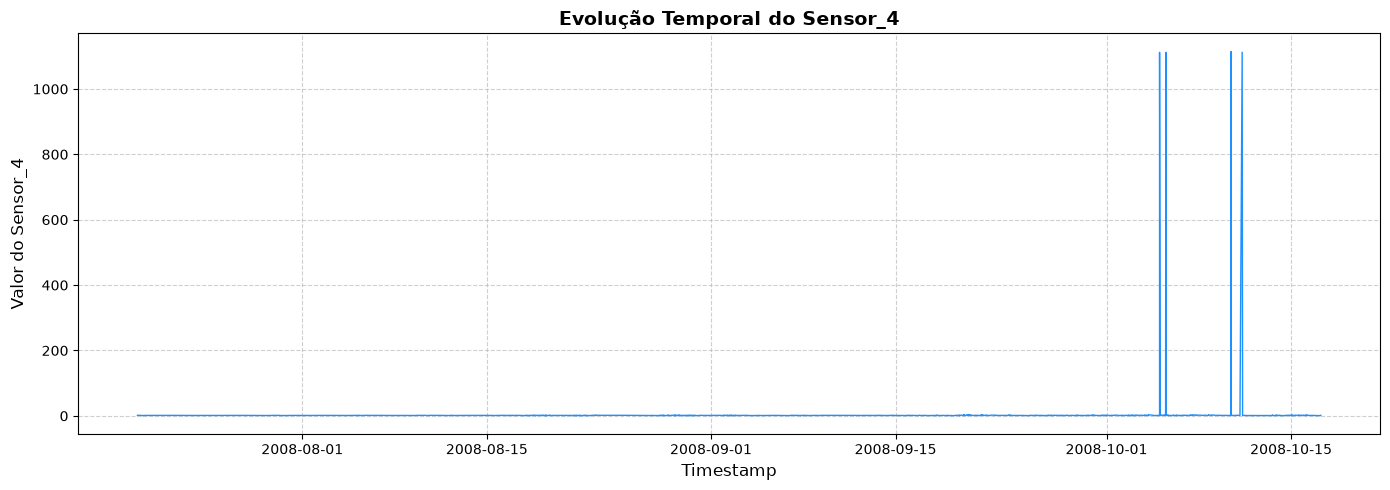

In [25]:
# A ordenar o DataFrame por timestamp para garantir a sequência temporal correta
df_sorted = df_clean.sort_values('timestamp')

# A traçar o gráfico do valor do Sensor_4 ao longo do tempo
plt.figure(figsize=(14, 5))
plt.plot(df_sorted['timestamp'], df_sorted['Sensor_4'], color='dodgerblue', linewidth=1.0)
plt.title("Evolução Temporal do Sensor_4", fontsize=14, fontweight='bold')
plt.xlabel("Timestamp", fontsize=12)
plt.ylabel("Valor do Sensor_4", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Prompt:** Plotar o valor do sensor_4 ao longo do tempo e indicar com um marcador diferente o momento em que o alvo é 1 

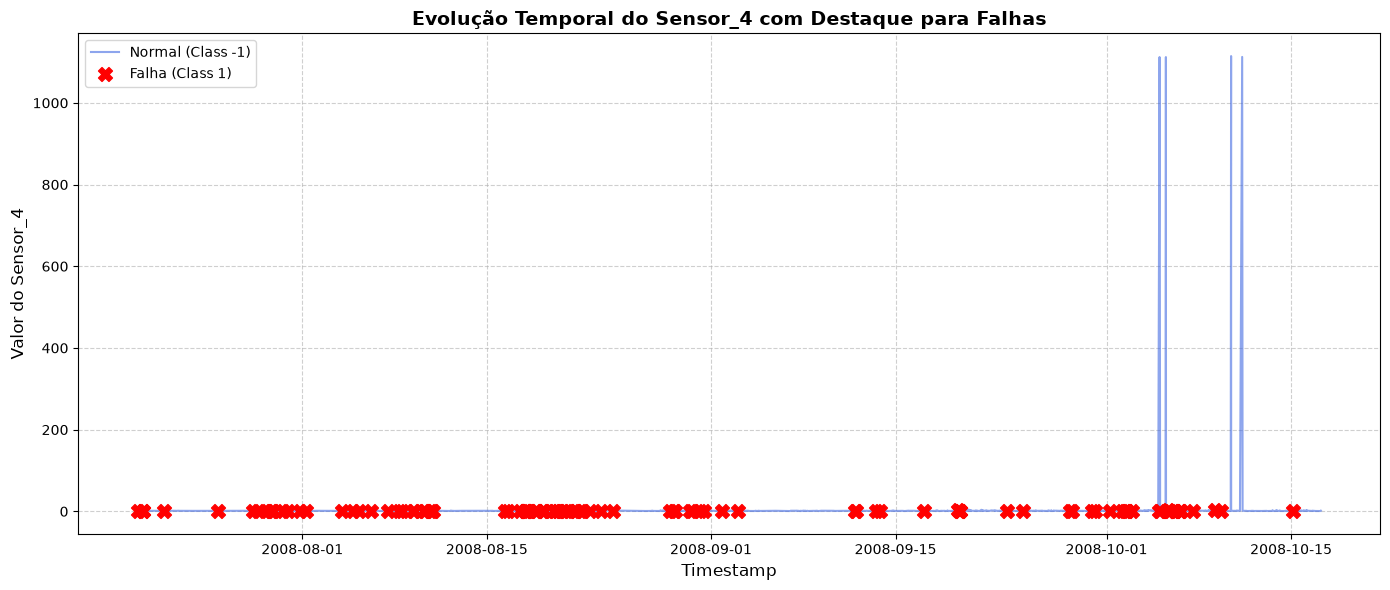

In [26]:
# Separando o DataFrame em dois grupos com base na classe ('class')
# Classe -1 (Normal) e Classe 1 (Falha)
df_normal = df_clean[df_clean['class'] == -1]
df_falha = df_clean[df_clean['class'] == 1]

# Plotando a série temporal do Sensor_4
plt.figure(figsize=(14, 6))

# Pontos normais (classe -1)
plt.plot(df_normal['timestamp'], df_normal['Sensor_4'], color='royalblue', alpha=0.6, label='Normal (Class -1)')

# Momentos de falha (classe 1) destacados com um marcador diferente
plt.scatter(df_falha['timestamp'], df_falha['Sensor_4'], color='red', marker='X', s=100, zorder=5, label='Falha (Class 1)')

plt.title("Evolução Temporal do Sensor_4 com Destaque para Falhas", fontsize=14, fontweight='bold')
plt.xlabel("Timestamp", fontsize=12)
plt.ylabel("Valor do Sensor_4", fontsize=12)
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

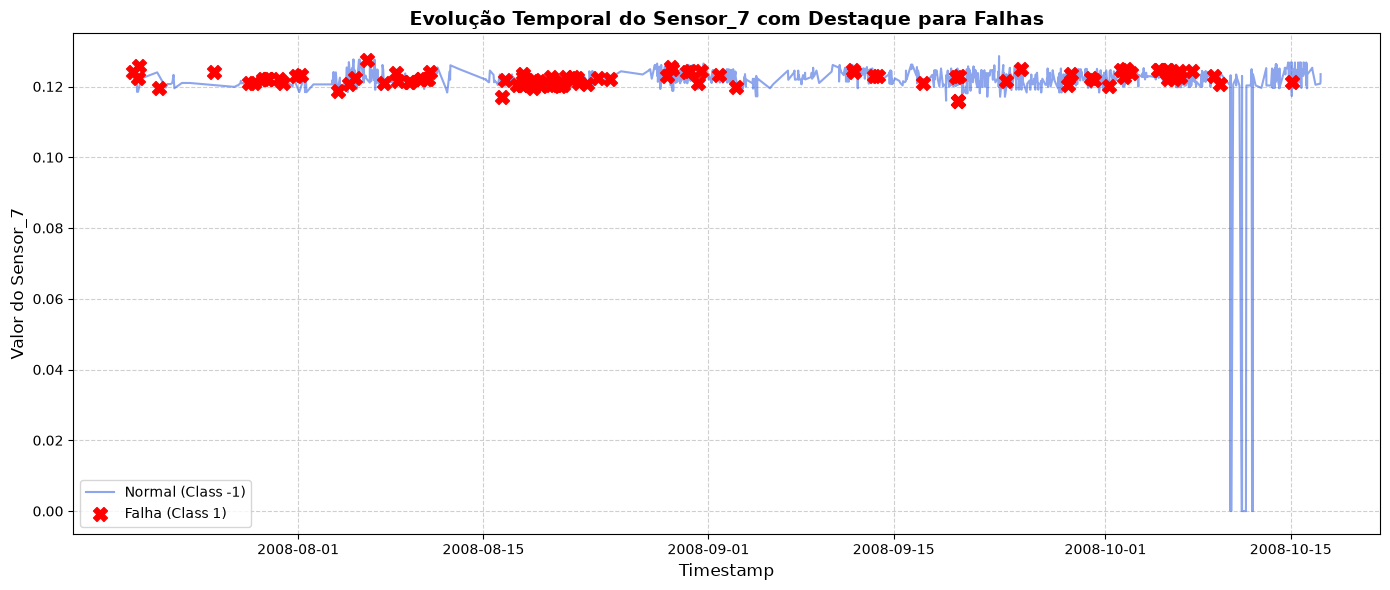

In [27]:
# Separando o DataFrame em dois grupos com base na classe ('class')
# Classe -1 (Normal) e Classe 1 (Falha)
df_normal = df_clean[df_clean['class'] == -1]
df_falha = df_clean[df_clean['class'] == 1]

# Plotando a série temporal do Sensor_7
plt.figure(figsize=(14, 6))

# Pontos normais (classe -1)
plt.plot(df_normal['timestamp'], df_normal['Sensor_7'], color='royalblue', alpha=0.6, label='Normal (Class -1)')

# Momentos de falha (classe 1) destacados com um marcador diferente
plt.scatter(df_falha['timestamp'], df_falha['Sensor_7'], color='red', marker='X', s=100, zorder=5, label='Falha (Class 1)')

plt.title("Evolução Temporal do Sensor_7 com Destaque para Falhas", fontsize=14, fontweight='bold')
plt.xlabel("Timestamp", fontsize=12)
plt.ylabel("Valor do Sensor_7", fontsize=12)
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Prompt:** Realize o split e pré-processamento 

In [28]:
# 1. Separando as features (X) da variável alvo (y)
# Excluindo colunas que não são sensores nem alvo (como 'timestamp' e 'class')
drop_cols = ['timestamp', 'class']
X = df_clean.drop(columns=[col for col in drop_cols if col in df_clean.columns])
y = df_clean['class']

# 2. Realizando o split estratificado (essencial devido ao desbalanceamento das classes)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=RANDOM_STATE, 
    stratify=y
)

# 3. Normalização dos dados (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convertendo de volta para DataFrame para manter os nomes das colunas (opcional, útil para inspeção)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

# Checagem de sanidade
print(f"Shape de X_train: {X_train_scaled.shape}")
print(f"Shape de X_test: {X_test_scaled.shape}")
print(f"Distribuição de classes em y_train:\n{y_train.value_counts(normalize=True) * 100}")
print(f"Distribuição de classes em y_test:\n{y_test.value_counts(normalize=True) * 100}")

Shape de X_train: (1253, 474)
Shape de X_test: (314, 474)
Distribuição de classes em y_train:
class
-1    93.375898
 1     6.624102
Name: proportion, dtype: float64
Distribuição de classes em y_test:
class
-1    93.312102
 1     6.687898
Name: proportion, dtype: float64


# SVM - Support Vector Machine

**Prompt**: Como fazer a otimização de hiperparâmetros e mostrar em forma de gráfico os resultados da otimização x os hiperparâmetros (C, gamma, kernel), sem realizar a validação cruzada estratificada? 

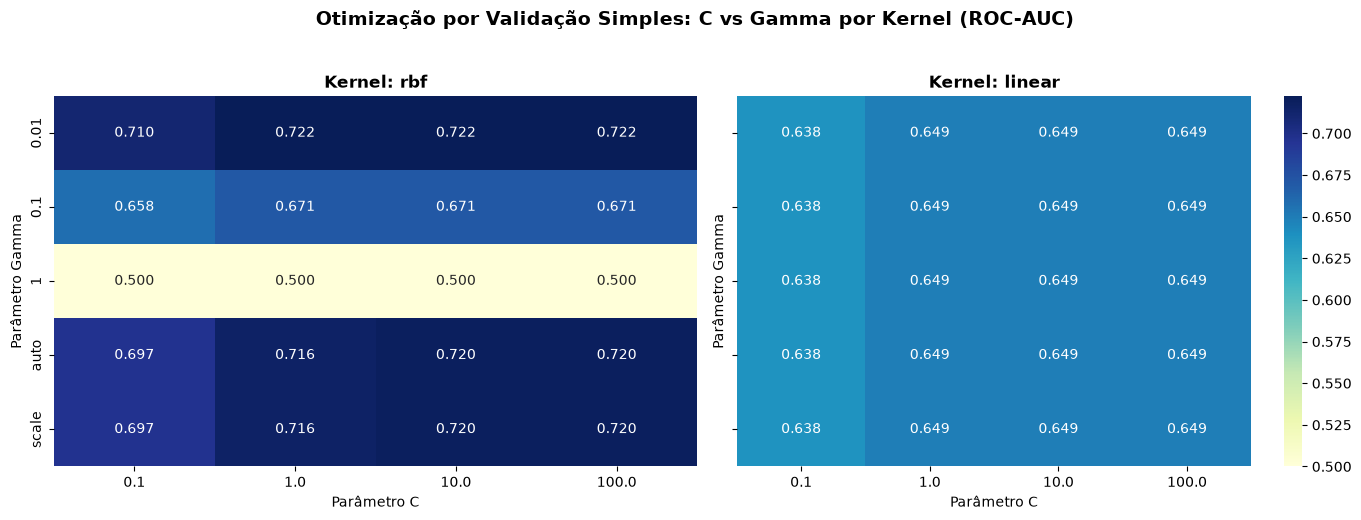

Melhores Hiperparâmetros: C=1.0, gamma=0.01, kernel=rbf
Melhor Score (ROC-AUC) na Validação: 0.7225


In [40]:
# 1. Criando um conjunto de validação dedicado a partir dos dados de treino (sem Cross-Validation)
X_sub_train, X_val, y_sub_train, y_val = train_test_split(
    X_train_scaled, y_train, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_train
)

# 2. Definindo o espaço de hiperparâmetros
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear']
}

# 3. Loop manual para testar cada combinação e avaliar no conjunto de validação
results = []
for params in ParameterGrid(param_grid):
    # Instanciando o modelo com os parâmetros atuais
    model = SVC(
        C=params['C'],
        gamma=params['gamma'],
        kernel=params['kernel'],
        class_weight='balanced',
        random_state=42
    )
    
    # Treinando no subconjunto de treino
    model.fit(X_sub_train, y_sub_train)
    
    # Calculando o ROC-AUC utilizando a função de decisão (mais rápido e evita uso de probabilidade calibrada)
    y_scores = model.decision_function(X_val)
    score = roc_auc_score(y_val, y_scores)
    
    results.append({
        'C': params['C'],
        'gamma': params['gamma'],
        'kernel': params['kernel'],
        'val_roc_auc': score
    })

# Convertendo os resultados em DataFrame
results_df = pd.DataFrame(results)

# Convertendo parâmetros para string para facilitar o mapeamento em tabela pivot
results_df['param_C_str'] = results_df['C'].astype(str)
results_df['param_gamma_str'] = results_df['gamma'].astype(str)

# 4. Criando os gráficos de calor (Heatmaps) por Kernel
kernels = results_df['kernel'].unique()
fig, axes = plt.subplots(1, len(kernels), figsize=(7 * len(kernels), 5), sharey=True)

if len(kernels) == 1:
    axes = [axes]

for idx, kernel in enumerate(kernels):
    ax = axes[idx]
    subset = results_df[results_df['kernel'] == kernel]
    
    # Criando a tabela pivot
    pivot_table = subset.pivot(index='param_gamma_str', columns='param_C_str', values='val_roc_auc')
    
    sns.heatmap(
        pivot_table, 
        annot=True, 
        fmt=".3f", 
        cmap="YlGnBu", 
        ax=ax,
        cbar=(idx == len(kernels) - 1),
        vmin=results_df['val_roc_auc'].min(), 
        vmax=results_df['val_roc_auc'].max()
    )
    ax.set_title(f"Kernel: {kernel}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Parâmetro C", fontsize=10)
    ax.set_ylabel("Parâmetro Gamma", fontsize=10)

plt.suptitle("Otimização por Validação Simples: C vs Gamma por Kernel (ROC-AUC)", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 5. Exibindo os melhores parâmetros encontrados
best_row = results_df.loc[results_df['val_roc_auc'].idxmax()]
print(f"Melhores Hiperparâmetros: C={best_row['C']}, gamma={best_row['gamma']}, kernel={best_row['kernel']}")
print(f"Melhor Score (ROC-AUC) na Validação: {best_row['val_roc_auc']:.4f}")

**Prompt**: Como fazer a otimização de hiperparâmetros e mostrar em forma de gráfico os resultados da otimização x os hiperparâmetros (C, gamma, kernel), com a validação cruzada estratificada?

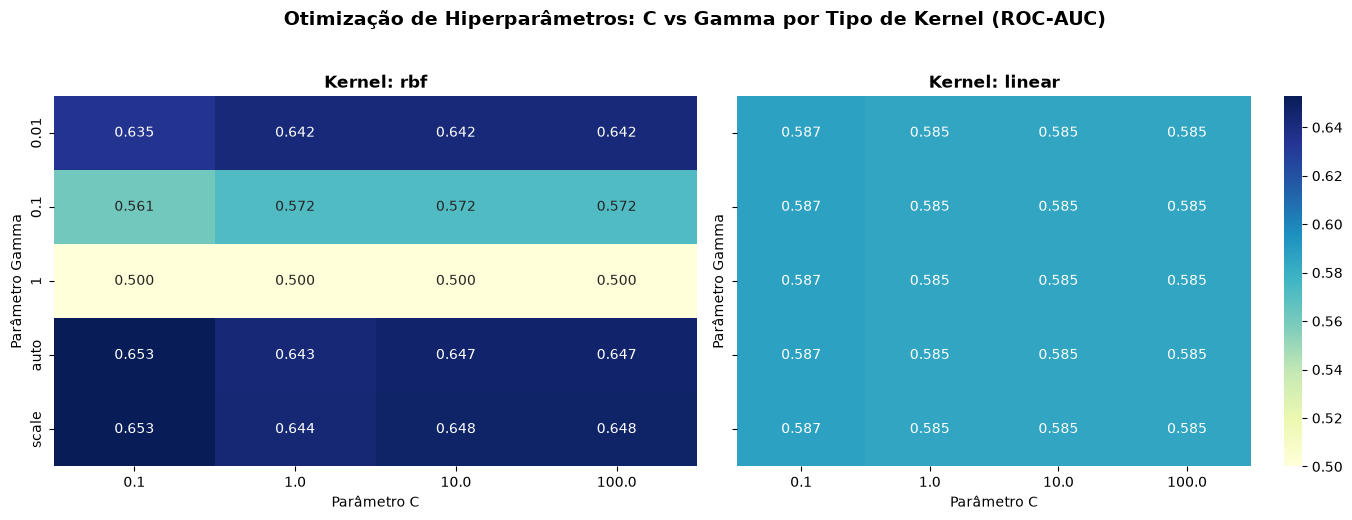

Melhores Hiperparâmetros: {'C': 0.1, 'gamma': 'auto', 'kernel': 'rbf'}
Melhor Score (ROC-AUC) na Validação Cruzada: 0.6529


In [42]:
# 1. Definindo o espaço de hiperparâmetros focando em C, gamma e kernel
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear'] # Você pode adicionar 'poly' ou 'sigmoid' se desejar
}

# 2. Configurando a validação cruzada estratificada
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 3. Configurando o GridSearchCV otimizando para ROC-AUC
grid_search = GridSearchCV(
    estimator=SVC(class_weight='balanced', random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv_strategy,
    n_jobs=-1
)

# Executando a busca
grid_search.fit(X_train_scaled, y_train)

# 4. Extraindo os resultados para visualização
results_df = pd.DataFrame(grid_search.cv_results_)

# Convertendo parâmetros para string para facilitar o mapeamento em tabela pivot
results_df['param_C_str'] = results_df['param_C'].astype(str)
results_df['param_gamma_str'] = results_df['param_gamma'].astype(str)

# 5. Criando gráficos de calor (Heatmaps) lado a lado para cada Kernel
kernels = results_df['param_kernel'].unique()
fig, axes = plt.subplots(1, len(kernels), figsize=(7 * len(kernels), 5), sharey=True)

# Garante que 'axes' seja tratável como lista mesmo se houver apenas 1 kernel
if len(kernels) == 1:
    axes = [axes]

for idx, kernel in enumerate(kernels):
    ax = axes[idx]
    # Filtra o subconjunto de resultados para o kernel atual
    subset = results_df[results_df['param_kernel'] == kernel]
    
    # Cria a matriz pivot para o heatmap (C nas colunas, gamma nas linhas)
    pivot_table = subset.pivot(index='param_gamma_str', columns='param_C_str', values='mean_test_score')
    
    sns.heatmap(
        pivot_table, 
        annot=True, 
        fmt=".3f", 
        cmap="YlGnBu", 
        ax=ax,
        cbar=(idx == len(kernels) - 1), # Mostra a barra de cores apenas no último gráfico
        vmin=results_df['mean_test_score'].min(), 
        vmax=results_df['mean_test_score'].max()
    )
    ax.set_title(f"Kernel: {kernel}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Parâmetro C", fontsize=10)
    ax.set_ylabel("Parâmetro Gamma", fontsize=10)

plt.suptitle("Otimização de Hiperparâmetros: C vs Gamma por Tipo de Kernel (ROC-AUC)", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Exibindo os melhores parâmetros encontrados
print(f"Melhores Hiperparâmetros: {grid_search.best_params_}")
print(f"Melhor Score (ROC-AUC) na Validação Cruzada: {grid_search.best_score_:.4f}")

 **Prompt**: Faça a Modelagem e Avaliação de Machine Learning para o seguinte algoritmo: SVM evidenciando os parâmetros 'C', 'gamma' e 'kernel', deixando em comentários na mesma linha as principais variantes para cada um dos hiperparâmetros.


In [53]:
# 1. Instanciando o classificador SVC evidenciando os hiperparâmetros 'C', 'gamma' e 'kernel'
# com as principais variantes comentadas diretamente na mesma linha.
base_svm = SVC(
    C=1.0,             # Parâmetro de regularização (C): variantes comuns [0.1, 1, 10, 100]
    gamma=0.01,     # Coeficiente do kernel (gamma): variantes comuns ['scale', 'auto', 0.01, 0.1, 1]
    kernel='rbf',      # Tipo de função do kernel: variantes comuns ['linear', 'poly', 'rbf', 'sigmoid']
    class_weight='balanced',
    random_state=RANDOM_STATE
)

# 2. Utilizando o CalibratedClassifierCV para calibração de probabilidades sem avisos de depreciação
svm_model = CalibratedClassifierCV(base_svm, ensemble=False)

# 3. Treinando o modelo com os dados de treino normalizados
svm_model.fit(X_train_scaled, y_train)

# 4. Realizando previsões no conjunto de teste
y_pred = svm_model.predict(X_test_scaled)
y_proba = svm_model.predict_proba(X_test_scaled)[:, 1]

# 5. Avaliação de Desempenho
print("--- Matriz de Confusão ---")
print(confusion_matrix(y_test, y_pred))

print("\n--- Relatório de Classificação ---")
print(classification_report(y_test, y_pred, zero_division=0))

# Calculando a métrica ROC-AUC
roc_auc = roc_auc_score(y_test, y_proba)
print(f"\nROC-AUC Score: {roc_auc:.4f}")

--- Matriz de Confusão ---
[[293   0]
 [ 21   0]]

--- Relatório de Classificação ---
              precision    recall  f1-score   support

          -1       0.93      1.00      0.97       293
           1       0.00      0.00      0.00        21

    accuracy                           0.93       314
   macro avg       0.47      0.50      0.48       314
weighted avg       0.87      0.93      0.90       314


ROC-AUC Score: 0.6457


**Prompt**: Como ajustar o limiar de descisão?

In [ ]:
# 1. Instanciando o classificador SVC evidenciando os hiperparâmetros 'C', 'gamma' e 'kernel'
base_svm = SVC(
    C=1.0,               # Parâmetro de regularização (C): variantes comuns [0.1, 1, 10, 100]
    gamma='scale',       # Coeficiente do kernel (gamma): variantes comuns ['scale', 'auto', 0.01, 0.1, 1]
    kernel='rbf',        # Tipo de função do kernel: variantes comuns ['linear', 'poly', 'rbf', 'sigmoid']
    class_weight='balanced',
    random_state=RANDOM_STATE
)

# 2. Utilizando o CalibratedClassifierCV para calibração de probabilidades
svm_model = CalibratedClassifierCV(base_svm, ensemble=False)

# 3. Treinando o modelo com os dados de treino normalizados
svm_model.fit(X_train_scaled, y_train)

# 4. Extraindo as probabilidades brutas da classe positiva (falha = 1) no conjunto de teste
y_proba = svm_model.predict_proba(X_test_scaled)[:, 1]

# =====================================================================
# 5. AJUSTE DO LIMIAR DE DECISÃO (Onde a mágica acontece)
# =====================================================================
# Em vez de aceitar o 0.5 padrão do predict(), definimos um limiar menor 
# para forçar o modelo a ser mais sensível às falhas.
custom_threshold = 0.15  # <--- Altere este valor para testar maior ou menor sensibilidade

# Se a probabilidade for maior ou igual ao limiar, classifica como Falha (1); caso contrário, Normal (-1)
y_pred_custom = np.where(y_proba >= custom_threshold, 1, -1)

# 6. Avaliação de Desempenho usando as premissas do Limiar Customizado
print(f"--- Matriz de Confusão (Threshold Customizado = {custom_threshold}) ---")
print(confusion_matrix(y_test, y_pred_custom))

print(f"\n--- Relatório de Classificação (Threshold Customizado = {custom_threshold}) ---")
print(classification_report(y_test, y_pred_custom, zero_division=0))

# Calculando a métrica ROC-AUC (Nota: O ROC-AUC permanece o mesmo, pois avalia todas as probabilidades possíveis)
roc_auc = roc_auc_score(y_test, y_proba)
print(f"\nROC-AUC Score: {roc_auc:.4f}")

--- Matriz de Confusão (Threshold Customizado = 0.15) ---
[[281  12]
 [ 18   3]]

--- Relatório de Classificação (Threshold Customizado = 0.15) ---
              precision    recall  f1-score   support

          -1       0.94      0.96      0.95       293
           1       0.20      0.14      0.17        21

    accuracy                           0.90       314
   macro avg       0.57      0.55      0.56       314
weighted avg       0.89      0.90      0.90       314


ROC-AUC Score: 0.6239


**Prompt**: Como encontrar o Limiar Ideal automaticamente usando a curva Precision-Recall?

In [59]:
# 1. Calculando precisão, recall e limiares disponíveis
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba_test, pos_label=1)

# 2. Encontrando o índice onde o F1-score (ou uma meta de Recall desejada, ex: Recall >= 0.80) é otimizado
# Exemplo: Buscando o limiar que nos dê um bom compromisso
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_index = np.argmax(f1_scores)
optimal_threshold = thresholds[best_index]

print(f"Limiar Ótimo Sugerido pela Curva Precision-Recall: {optimal_threshold:.4f}")



# 3. Aplicando o limiar ótimo encontrado matematicamente
y_pred_optimal = np.where(y_proba_test >= optimal_threshold, 1, -1)


# Avaliação de Desempenho usando as premissas do Limiar Customizado
print(f"--- Matriz de Confusão (Threshold Customizado = {optimal_threshold:.4f}) ---")
print(confusion_matrix(y_test, y_pred_optimal))

print("\n--- Relatório com Limiar Ótimo ---")
print(classification_report(y_test, y_pred_optimal, zero_division=0))

Limiar Ótimo Sugerido pela Curva Precision-Recall: 0.1013
--- Matriz de Confusão (Threshold Customizado = 0.1013) ---
[[249  44]
 [ 12   9]]

--- Relatório com Limiar Ótimo ---
              precision    recall  f1-score   support

          -1       0.95      0.85      0.90       293
           1       0.17      0.43      0.24        21

    accuracy                           0.82       314
   macro avg       0.56      0.64      0.57       314
weighted avg       0.90      0.82      0.86       314



## Compromisso de negócio (Trade-off):

Se a prioridade da fábrica for zero defeitos saindo da linha: Um recall de 43% ainda pode ser baixo; seria necessário abaixar ainda mais o limiar para tentar pegar mais falhas, aceitando um volume maior de alarmes falsos.

Se o custo de descartar peças boas for muito alto: O limiar atual pode ser refinado para encontrar o ponto ideal onde o custo do alarme falso compensa o custo da falha que escapa.

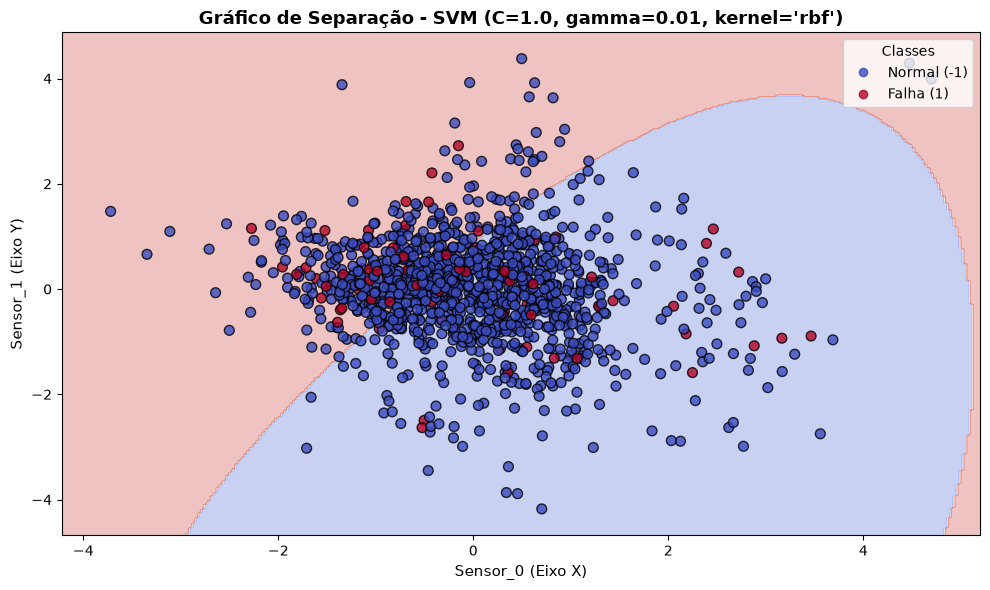

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

# 1. Selecionando duas features para a visualização 2D:
# Índice 0 representa o Sensor_0, e escolhemos o índice 1 (ou outro sensor/feature) para o eixo Y.
# Certifique-se de que X_train_scaled esteja no formato numpy array ou ajuste para ['Sensor_0', 'Outro_Sensor'] se for DataFrame.
if hasattr(X_train_scaled, "iloc"):
    X_viz = X_train_scaled.iloc[:, [0, 1]].values
    feature_names = X_train_scaled.columns[:2]
else:
    X_viz = X_train_scaled[:, [0, 1]]
    feature_names = ["Sensor_0", "Sensor_1"]

y_viz = y_train.values if hasattr(y_train, "values") else y_train

# 2. Instanciando e treinando o SVM com os parâmetros solicitados
svm_2d = SVC(
    C=1.0, 
    gamma=0.01, 
    kernel='rbf', 
    class_weight='balanced', 
    random_state=42
)
svm_2d.fit(X_viz, y_viz)

# 3. Criando uma grade (meshgrid) para mapear a fronteira de decisão em todo o plano
x_min, x_max = X_viz[:, 0].min() - 0.5, X_viz[:, 0].max() + 0.5
y_min, y_max = X_viz[:, 1].min() - 0.5, X_viz[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Prevendo os rótulos para cada ponto da grade
Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 4. Plotando o gráfico de separação (Fronteira de Decisão)
plt.figure(figsize=(10, 6))

# Contorno colorido mostrando a área de decisão de cada classe
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)

# Gráfico de dispersão (scatter) com os pontos reais dos dados
scatter = plt.scatter(
    X_viz[:, 0], X_viz[:, 1], 
    c=y_viz, 
    edgecolors='k', 
    cmap=plt.cm.coolwarm, 
    s=50, 
    alpha=0.8
)

plt.title("Gráfico de Separação - SVM (C=1.0, gamma=0.01, kernel='rbf')", fontsize=13, fontweight='bold')
plt.xlabel(f"{feature_names[0]} (Eixo X)", fontsize=11)
plt.ylabel(f"{feature_names[1]} (Eixo Y)", fontsize=11)

# Legenda personalizada para as classes (-1 e 1)
handles, labels = scatter.legend_elements()
plt.legend(handles, ["Normal (-1)", "Falha (1)"], title="Classes", loc="upper right")

plt.tight_layout()
plt.show()

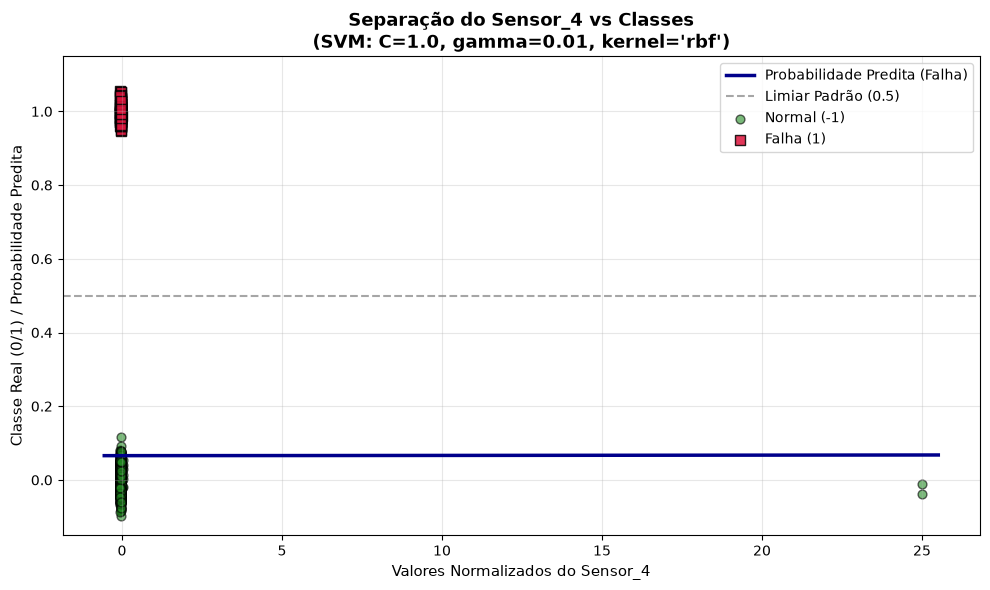

In [67]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

# 1. Extraindo apenas o Sensor_0 (primeira coluna) dos dados normalizados de treino
if hasattr(X_train_scaled, "iloc"):
    X_single = X_train_scaled.iloc[:, [4]].values
    feature_name = X_train_scaled.columns[4]
else:
    X_single = X_train_scaled[:, [4]]
    feature_name = "Sensor_4"

y_train_arr = y_train.values if hasattr(y_train, "values") else y_train

# 2. Instanciando e treinando o SVM restrito a 1 feature (Sensor_4)
base_svm = SVC(
    C=1.0, 
    gamma=0.01, 
    kernel='rbf', 
    class_weight='balanced', 
    random_state=42
)
# Calibrando para extrair probabilidades contínuas suaves
model_1d = CalibratedClassifierCV(base_svm, ensemble=False)
model_1d.fit(X_single, y_train_arr)

# 3. Criando uma grade contínua de valores para traçar a curva de probabilidade do kernel RBF
x_min, x_max = X_single.min() - 0.5, X_single.max() + 0.5
x_grid = np.linspace(x_min, x_max, 500).reshape(-1, 1)
y_proba_grid = model_1d.predict_proba(x_grid)[:, 1]

# 4. Convertendo as classes originais (-1 e 1) para formato binário (0 e 1) para visualização no eixo Y
y_binary = np.where(y_train_arr == 1, 1, 0)

# 5. Plotando o gráfico de separação 1D
plt.figure(figsize=(10, 6))

# Curva de probabilidade predita pelo SVM RBF
plt.plot(
    x_grid, y_proba_grid, 
    color='darkblue', linewidth=2.5, 
    label='Probabilidade Predita (Falha)'
)
plt.axhline(
    0.5, color='gray', linestyle='--', alpha=0.7, 
    label='Limiar Padrão (0.5)'
)

# Adicionando um leve ruído (jitter) vertical nos pontos reais para evitar sobreposição visual
np.random.seed(42)
y_jitter = y_binary + np.random.normal(0, 0.03, size=len(y_binary))

# Scatter plot das amostras reais normais (-1 / 0)
plt.scatter(
    X_single[y_binary == 0], y_jitter[y_binary == 0], 
    color='forestgreen', alpha=0.6, edgecolors='k', s=40, 
    label='Normal (-1)'
)

# Scatter plot das amostras reais com falha (1)
plt.scatter(
    X_single[y_binary == 1], y_jitter[y_binary == 1], 
    color='crimson', alpha=0.85, edgecolors='k', s=60, marker='s', 
    label='Falha (1)'
)

plt.title(f"Separação do {feature_name} vs Classes\n(SVM: C=1.0, gamma=0.01, kernel='rbf')", fontsize=13, fontweight='bold')
plt.xlabel(f"Valores Normalizados do {feature_name}", fontsize=11)
plt.ylabel("Classe Real (0/1) / Probabilidade Predita", fontsize=11)
plt.ylim(-0.15, 1.15)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

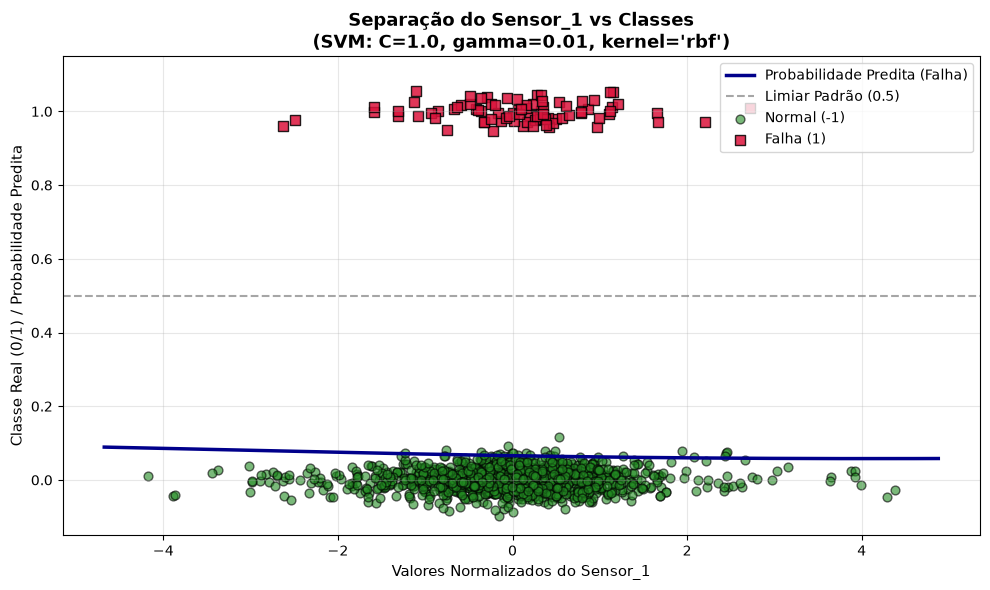

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

# 1. Extraindo apenas o Sensor_1 (primeira coluna) dos dados normalizados de treino
if hasattr(X_train_scaled, "iloc"):
    X_single = X_train_scaled.iloc[:, [1]].values
    feature_name = X_train_scaled.columns[1]
else:
    X_single = X_train_scaled[:, [1]]
    feature_name = "Sensor_1"

y_train_arr = y_train.values if hasattr(y_train, "values") else y_train

# 2. Instanciando e treinando o SVM restrito a 1 feature (Sensor_1)
base_svm = SVC(
    C=1.0, 
    gamma=0.01, 
    kernel='rbf', 
    class_weight='balanced', 
    random_state=42
)
# Calibrando para extrair probabilidades contínuas suaves
model_1d = CalibratedClassifierCV(base_svm, ensemble=False)
model_1d.fit(X_single, y_train_arr)

# 3. Criando uma grade contínua de valores para traçar a curva de probabilidade do kernel RBF
x_min, x_max = X_single.min() - 0.5, X_single.max() + 0.5
x_grid = np.linspace(x_min, x_max, 500).reshape(-1, 1)
y_proba_grid = model_1d.predict_proba(x_grid)[:, 1]

# 4. Convertendo as classes originais (-1 e 1) para formato binário (0 e 1) para visualização no eixo Y
y_binary = np.where(y_train_arr == 1, 1, 0)

# 5. Plotando o gráfico de separação 1D
plt.figure(figsize=(10, 6))

# Curva de probabilidade predita pelo SVM RBF
plt.plot(
    x_grid, y_proba_grid, 
    color='darkblue', linewidth=2.5, 
    label='Probabilidade Predita (Falha)'
)
plt.axhline(
    0.5, color='gray', linestyle='--', alpha=0.7, 
    label='Limiar Padrão (0.5)'
)

# Adicionando um leve ruído (jitter) vertical nos pontos reais para evitar sobreposição visual
np.random.seed(42)
y_jitter = y_binary + np.random.normal(0, 0.03, size=len(y_binary))

# Scatter plot das amostras reais normais (-1 / 0)
plt.scatter(
    X_single[y_binary == 0], y_jitter[y_binary == 0], 
    color='forestgreen', alpha=0.6, edgecolors='k', s=40, 
    label='Normal (-1)'
)

# Scatter plot das amostras reais com falha (1)
plt.scatter(
    X_single[y_binary == 1], y_jitter[y_binary == 1], 
    color='crimson', alpha=0.85, edgecolors='k', s=60, marker='s', 
    label='Falha (1)'
)

plt.title(f"Separação do {feature_name} vs Classes\n(SVM: C=1.0, gamma=0.01, kernel='rbf')", fontsize=13, fontweight='bold')
plt.xlabel(f"Valores Normalizados do {feature_name}", fontsize=11)
plt.ylabel("Classe Real (0/1) / Probabilidade Predita", fontsize=11)
plt.ylim(-0.15, 1.15)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

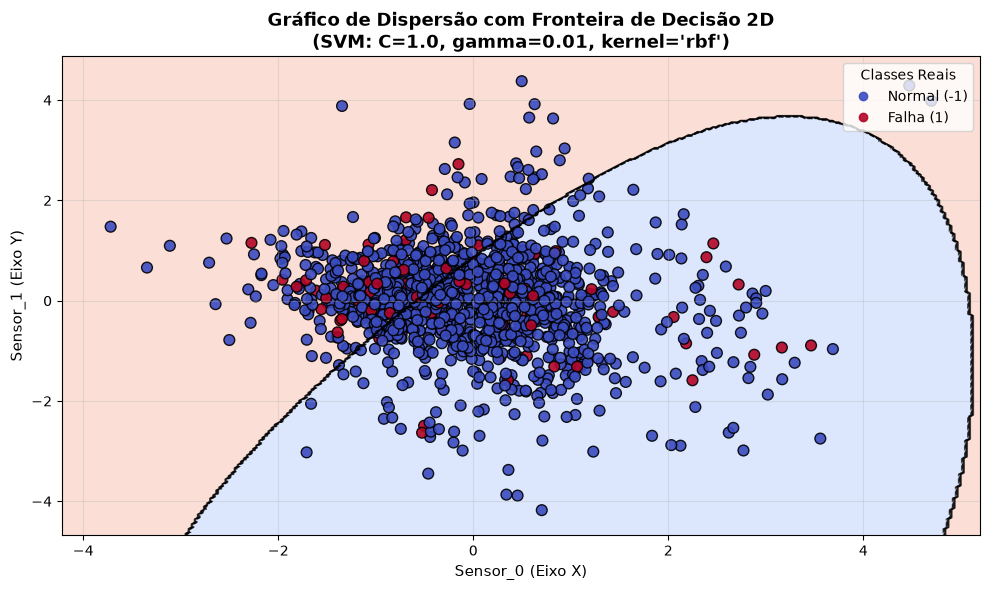

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

# 1. Selecionando exatamente 2 features (ex: Sensor_0 e Sensor_1) para o espaço 2D
if hasattr(X_train_scaled, "iloc"):
    X_2d = X_train_scaled.iloc[:, [0, 1]].values
    feature_names = X_train_scaled.columns[:2]
else:
    X_2d = X_train_scaled[:, [0, 1]]
    feature_names = ["Sensor_0", "Sensor_1"]

y_train_arr = y_train.values if hasattr(y_train, "values") else y_train

# 2. Treinando o modelo SVM com os parâmetros desejados
svm_boundary_model = SVC(
    C=1.0, 
    gamma=0.01, 
    kernel='rbf', 
    class_weight='balanced', 
    random_state=42
)
svm_boundary_model.fit(X_2d, y_train_arr)

# 3. Criando a malha (meshgrid) para cobrir todo o espaço do gráfico
x_min, x_max = X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5
y_min, y_max = X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Prevendo as classes para cada ponto da malha de fundo
Z = svm_boundary_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 4. Plotando o Gráfico de Dispersão com a Fronteira de Decisão
plt.figure(figsize=(10, 6))

# Contorno colorido de fundo (Fronteira de Decisão)
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm, levels=[-1.5, 0.0, 1.5])
plt.contour(xx, yy, Z, colors='k', linewidths=1, alpha=0.5) # Linha divisória exata

# Gráfico de dispersão (Scatter Plot) com os dados reais
scatter = plt.scatter(
    X_2d[:, 0], X_2d[:, 1], 
    c=y_train_arr, 
    edgecolors='k', 
    cmap=plt.cm.coolwarm, 
    s=60, 
    alpha=0.9
)

# Customização do Gráfico
plt.title("Gráfico de Dispersão com Fronteira de Decisão 2D\n(SVM: C=1.0, gamma=0.01, kernel='rbf')", fontsize=13, fontweight='bold')
plt.xlabel(f"{feature_names[0]} (Eixo X)", fontsize=11)
plt.ylabel(f"{feature_names[1]} (Eixo Y)", fontsize=11)

# Legenda clara para as classes
handles, _ = scatter.legend_elements()
plt.legend(handles, ["Normal (-1)", "Falha (1)"], title="Classes Reais", loc="upper right", frameon=True)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()